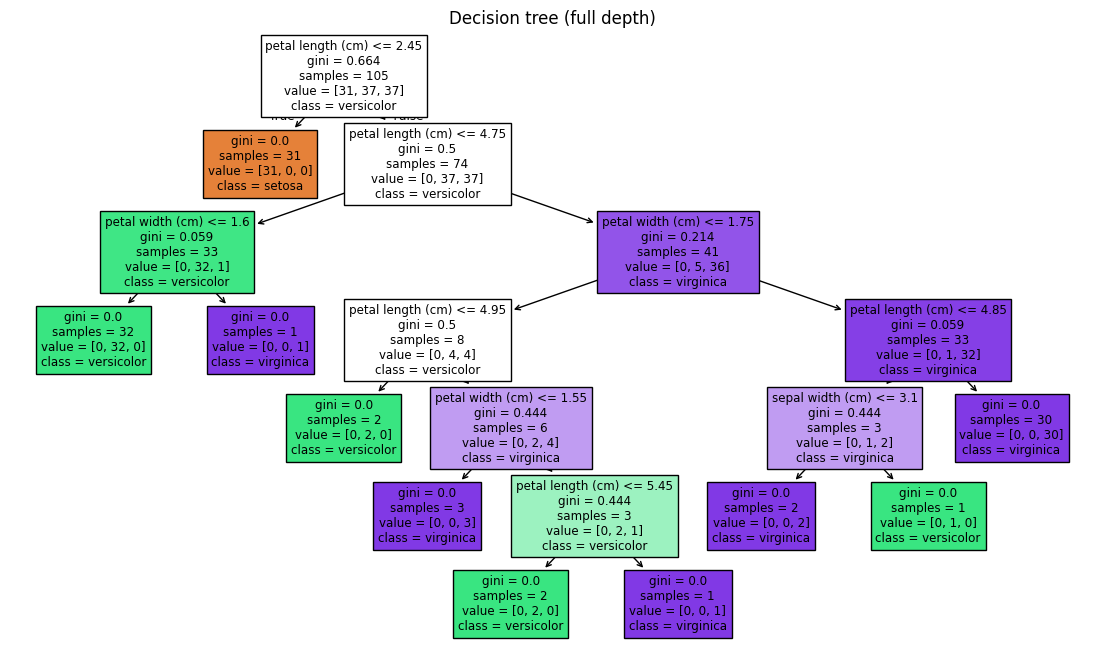

In [1]:
#Task 1: Train a decision tree on Iris and plot it
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42)

dt = DecisionTreeClassifier(random_state=42)
dt.fit(xtr, ytr)

plt.figure(figsize=(14, 8))
plot_tree(dt, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=True)
plt.title("Decision tree (full depth)")
plt.show()

In [2]:
#Task 2: Compare gini and entropy
for crit in ["gini", "entropy"]:
    t = DecisionTreeClassifier(criterion=crit, random_state=42)
    t.fit(xtr, ytr)
    print(crit, "accuracy:", round(accuracy_score(yte, t.predict(xte)), 3))

# Gini and entropy give almost the same accuracy (1.0 and 0.978). The difference is only one test flower,
# so neither criterion is clearly better on Iris.

gini accuracy: 1.0
entropy accuracy: 0.978


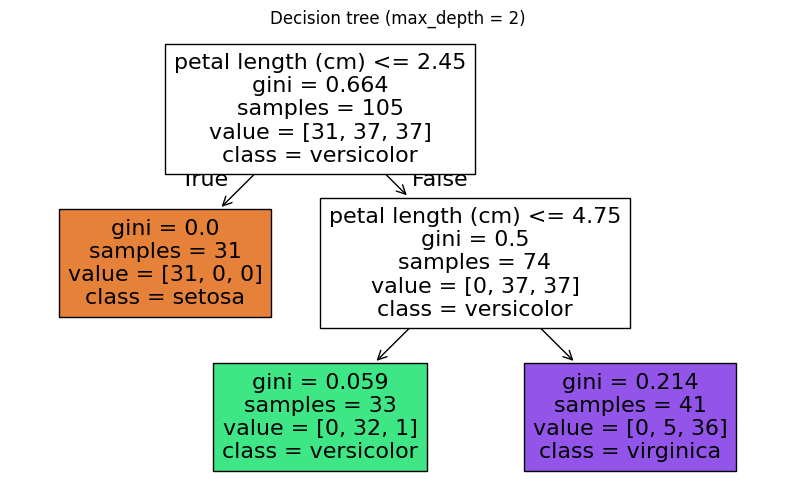

Full tree accuracy: 1.0
Depth 2 tree accuracy: 0.978


In [3]:
#Task 3: Limit max depth to 2 and plot the tree
dt2 = DecisionTreeClassifier(max_depth=2, random_state=42)
dt2.fit(xtr, ytr)

plt.figure(figsize=(10, 6))
plot_tree(dt2, feature_names=iris.feature_names, class_names=list(iris.target_names), filled=True)
plt.title("Decision tree (max_depth = 2)")
plt.show()

print("Full tree accuracy:", round(accuracy_score(yte, dt.predict(xte)), 3))
print("Depth 2 tree accuracy:", round(accuracy_score(yte, dt2.predict(xte)), 3))

# The full tree has depth 6 and 10 leaves. The depth 2 tree has only 3 leaves.
# First split: petal length <= 2.45 separates setosa. Second split: petal length <= 4.75 separates versicolor and virginica.
# The leaves are now slightly mixed (a few flowers end up in the wrong class), so accuracy drops a little (1.0 to 0.978).
# The full tree keeps splitting to fix those last few flowers, but the small tree is much easier to read and less likely to overfit.

In [4]:
#Task 4: Feature importance of the Iris decision tree
import pandas as pd

imp = pd.Series(dt.feature_importances_, index=iris.feature_names)
print(imp.sort_values(ascending=False).round(3))

petal length (cm)    0.893
petal width (cm)     0.088
sepal width (cm)     0.019
sepal length (cm)    0.000
dtype: float64


Accuracy: 0.8


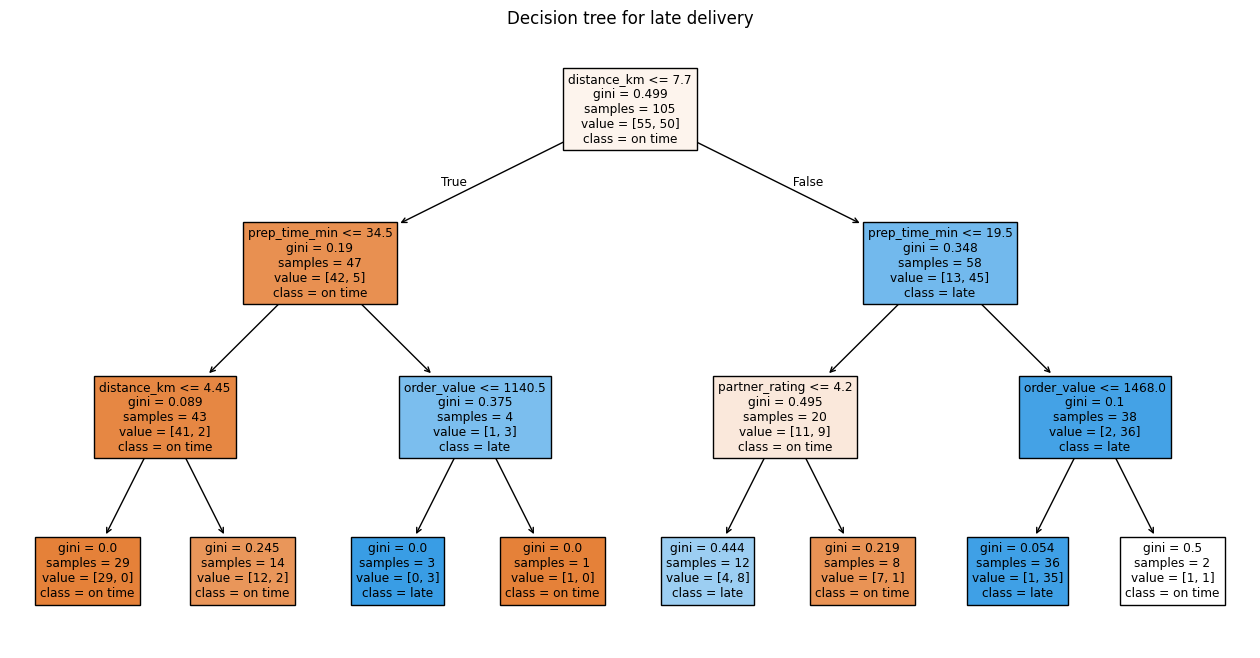

In [5]:
#Task 5: Decision tree on a food delivery dataset and its first three splits
fd = pd.read_csv("food_delivery.csv")
Xf = fd.drop(columns="late")
yf = fd["late"]
xtr, xte, ytr, yte = train_test_split(Xf, yf, test_size=0.3, random_state=1)

tf = DecisionTreeClassifier(max_depth=3, random_state=1)
tf.fit(xtr, ytr)
print("Accuracy:", round(accuracy_score(yte, tf.predict(xte)), 3))

plt.figure(figsize=(16, 8))
plot_tree(tf, feature_names=list(Xf.columns), class_names=["on time", "late"], filled=True)
plt.title("Decision tree for late delivery")
plt.show()

# Split 1: distance_km <= 7.70. Orders closer than about 7.7 km go left and are mostly on time, farther orders go right where most are late.
#          Distance separates on time and late orders best, so the tree uses it first.
# Split 2 (left side): prep_time_min <= 34.5. For nearby orders, only those with a very long preparation time (more than 34.5 minutes) are late.
# Split 3 (right side): prep_time_min <= 19.5. For far orders, if the food takes more than 19.5 minutes to prepare, almost all of them are late.
#          If it is quick to prepare, the tree needs more splits because the orders are mixed.